# Titanic Survival Prediction

This project aims to predict whether a passenger survived the Titanic disaster using Machine Learning techniques.

The notebook covers:
- Exploratory Data Analysis (EDA)
- Data Cleaning
- Feature Engineering
- Machine Learning Model Training
- Model Evaluation

Models implemented:
- Logistic Regression
- Decision Tree Classifier

## 1. Import Required Libraries

The following libraries are used for:
- Data manipulation
- Data visualization
- Machine learning model development

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## 2. Loading Dataset

The Titanic dataset contains information about passengers such as age, gender, passenger class, fare, and survival status.

The target variable is:

**Survived**
- 0 → Passenger did not survive
- 1 → Passenger survived

In [3]:
train_df = pd.read_csv("../data/train.csv")

# 3. Exploratory Data Analysis (EDA)

EDA helps us understand the structure of the dataset, identify patterns, and discover relationships between features and passenger survival.

In [4]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
train_df.shape

(891, 12)

In [7]:
train_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [8]:
train_df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

### Survival Distribution

Checking the number and proportion of passengers who survived versus those who did not.

In [9]:
# train_df["survived"].value_counts()
train_df['Survived'].value_counts()
train_df['Survived'].value_counts(normalize=True)


Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

### Survival Rate by Gender

Analyzing whether survival chances differed based on passenger gender.

In [10]:
train_df.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

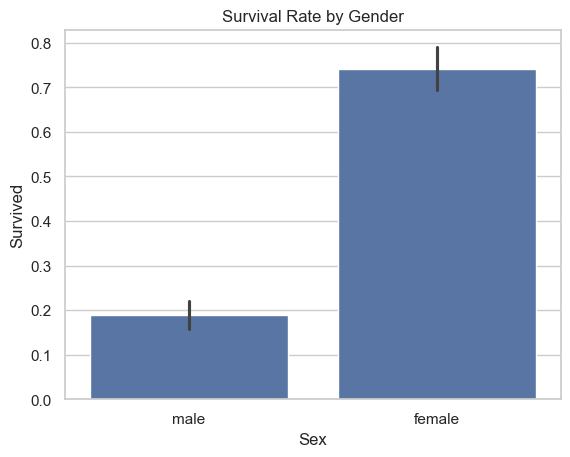

In [11]:
sns.barplot(x='Sex',y='Survived',data=train_df)
plt.title("Survival Rate by Gender")
plt.show()

### Survival Rate by Passenger Class

Analyzing the relationship between passenger class and survival probability.

In [12]:
train_df.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

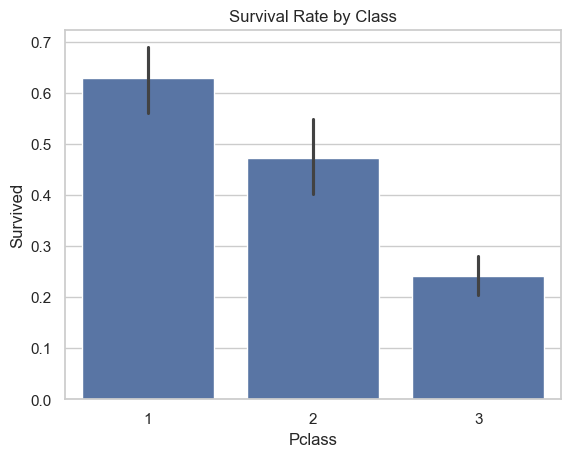

In [13]:
sns.barplot(x='Pclass',y='Survived',data=train_df)
plt.title("Survival Rate by Class")
plt.show()

In [14]:
train_df.groupby(['Pclass','Sex'])['Survived'].mean()

Pclass  Sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: Survived, dtype: float64

### Age Distribution and Survival Relationship

Studying the distribution of passenger ages and whether age influenced survival outcomes.

In [16]:
train_df['Age'].isnull().sum()

np.int64(177)

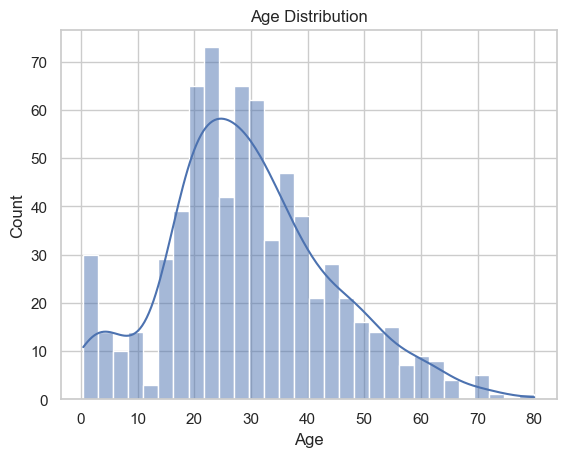

In [17]:
sns.histplot(train_df['Age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

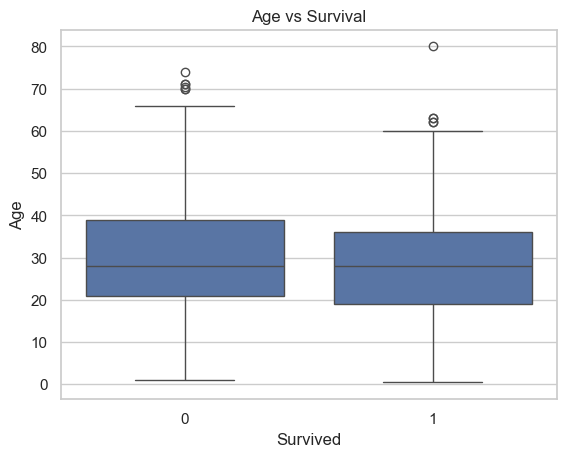

In [18]:
sns.boxplot(x='Survived', y='Age', data=train_df)
plt.title('Age vs Survival')
plt.show()


## 4. Data Cleaning and Preprocessing

Machine learning algorithms require clean numerical data.

The following preprocessing steps are performed:
- Handling missing values
- Encoding categorical variables
- Removing irrelevant features

In [19]:
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### Handling Missing Values

Missing values are handled using:
- Median imputation for numerical columns
- Mode imputation for categorical columns

In [21]:
df = train_df.copy()

In [22]:
df["Age"]=df["Age"].fillna(df["Age"].median())
df["Embarked"]=df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Fare"]=df["Fare"].fillna(df["Fare"].median())

### Encoding Categorical Features

Machine learning models cannot directly process text values.

Categorical variables such as Sex and Embarked are converted into numerical representations.

In [23]:
label_encoder=LabelEncoder()

df["Sex"]=label_encoder.fit_transform(df["Sex"])
df["Embarked"]=label_encoder.fit_transform(df["Embarked"])

### Removing Unnecessary Features

Columns such as Name, Ticket, Cabin, and PassengerId are removed because they either contain high-cardinality information or are not useful for prediction.

In [24]:
df=df.drop(columns=["PassengerId","Name","Ticket","Cabin"])

In [25]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


## 5. Splitting Dataset

The dataset is divided into:
- Training set → Used to train the model
- Testing set → Used to evaluate model performance

80% data is used for training and 20% for testing.

In [26]:
X=df.drop("Survived",axis=1)
y=df["Survived"]

In [27]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42)

## 6. Logistic Regression Model

Logistic Regression is a classification algorithm used to predict binary outcomes.

In this project:
- 0 represents non-survival
- 1 represents survival

In [28]:
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [29]:
lr_pred=lr.predict(X_test)

### Model Evaluation

The model is evaluated using:
- Accuracy Score
- Confusion Matrix
- Classification Report

In [30]:
print("Logistic Regression Accuracy:", accuracy_score(y_test,lr_pred))

Logistic Regression Accuracy: 0.8100558659217877


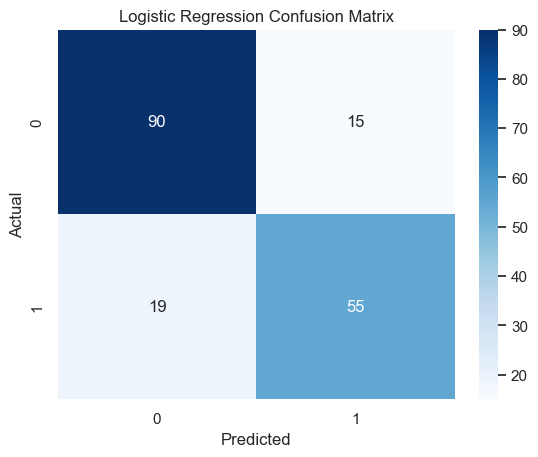

In [31]:
cm=confusion_matrix(y_test,lr_pred)

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [32]:
print(classification_report(y_test,lr_pred))

              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [33]:
dt=DecisionTreeClassifier(random_state=42)

dt.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [34]:
dt_pred=dt.predict(X_test)

In [35]:
print("Decision Tree Analysis:", accuracy_score(y_test,dt_pred))

Decision Tree Analysis: 0.7821229050279329


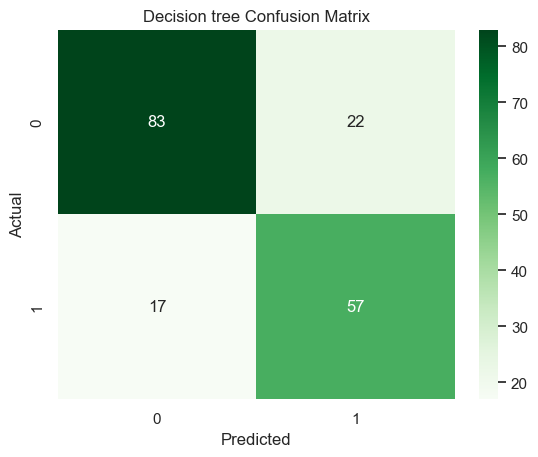

In [36]:
cm=confusion_matrix(y_test,dt_pred)

sns.heatmap(cm,annot=True,fmt="d",cmap="Greens")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision tree Confusion Matrix")
plt.show()

In [37]:
print(classification_report(y_test,dt_pred))

              precision    recall  f1-score   support

           0       0.83      0.79      0.81       105
           1       0.72      0.77      0.75        74

    accuracy                           0.78       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.78      0.78       179



In [39]:
importance=pd.Series(dt.feature_importances_,index=X.columns).sort_values(ascending=False)

importance

Sex         0.310280
Fare        0.242798
Age         0.217041
Pclass      0.111619
SibSp       0.056342
Parch       0.037738
Embarked    0.024181
dtype: float64

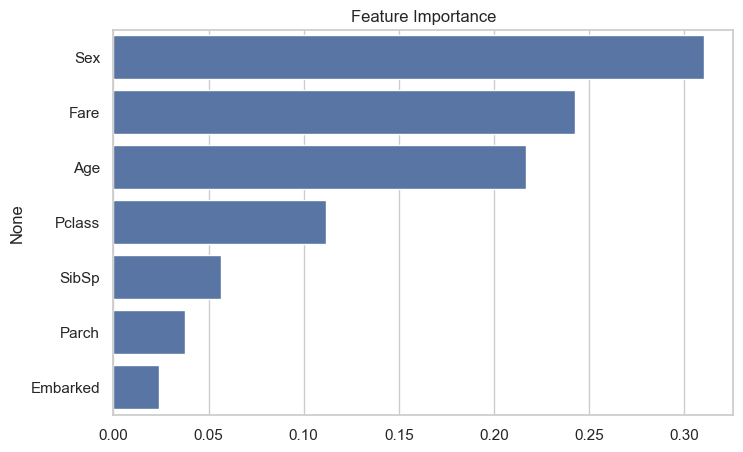

In [40]:
plt.figure(figsize=(8,5))

sns.barplot(x=importance.values,y=importance.index)

plt.title("Feature Importance")
plt.show()

In [42]:
results=pd.DataFrame({
    "Model": ["Logistic Regression","Decison Tree"],
    "Accuracy": [
        accuracy_score(y_test,lr_pred),
        accuracy_score(y_test,dt_pred)
    ]
})
results

,Model,Accuracy
0,Logistic Regression,0.810056
1,Decison Tree,0.782123


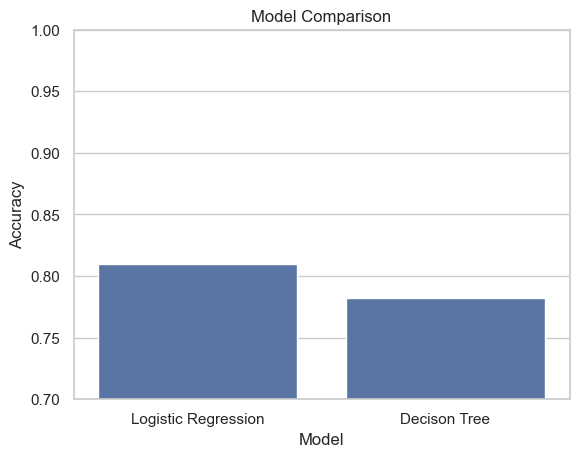

In [43]:
sns.barplot(
    x="Model",
    y="Accuracy",
    data=results
)

plt.ylim(0.7,1)

plt.title("Model Comparison")

plt.show()